In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
# 1) Environment check
import torch, sys
print("Python:", sys.version)
print("Torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("!! No GPU detected -- go to Settings (right sidebar) -> Accelerator -> GPU, then Save & re-run.")


Python: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
Torch: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4


In [2]:
# 2) Install the one extra package Kaggle doesn't ship by default (wfdb, for reading PTB-XL signals)
!pip install -q wfdb


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 1.4 MB/s eta 0:00:0000:0100:01


In [3]:
# 3) Auto-detect the PTB-XL root folder under /kaggle/input
#    (works regardless of which exact PTB-XL Kaggle dataset slug you added,
#    since Kaggle sometimes nests an extra folder level).
import glob, os

candidates = glob.glob('/kaggle/input/**/ptbxl_database.csv', recursive=True)
if candidates:
    PTBXL_ROOT = os.path.dirname(candidates[0])
    print("Found PTB-XL at:", PTBXL_ROOT)
    print("Contents:", os.listdir(PTBXL_ROOT)[:10])
else:
    PTBXL_ROOT = None
    print("No ptbxl_database.csv found under /kaggle/input.")
    print("Add the PTB-XL dataset via 'Add Input' in the right sidebar, then re-run this cell.")
    print("Falling back to synthetic data for now (see Sanity Check cell below).")


Found PTB-XL at: /kaggle/input/datasets/arshiaswain/ptb-xl-e/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3
Contents: ['records500', 'SHA256SUMS.txt', 'RECORDS', 'example_physionet.py', 'ptbxl_v103_changelog.txt', 'scp_statements.csv', 'ptbxl_database.csv', 'LICENSE.txt', 'ptbxl_v102_changelog.txt', 'records100']


In [4]:
%%writefile data_utils.py
"""
PTB-XL data loading utilities.

Expects the standard PTB-XL directory layout (as downloaded from PhysioNet):

    ptbxl_root/
        ptbxl_database.csv
        scp_statements.csv
        records100/  (or records500/)
            00000/
                00001_lr.dat / .hea   (100Hz version)
            ...

Download from: https://physionet.org/content/ptb-xl/1.0.3/
"""
import os
import ast
import numpy as np
import pandas as pd

try:
    import wfdb
    _HAS_WFDB = True
except ImportError:
    _HAS_WFDB = False


def load_ptbxl_metadata(root: str):
    """Load ptbxl_database.csv and scp_statements.csv, aggregate diagnostic
    superclasses/subclasses for each recording.

    Returns
    -------
    df : pd.DataFrame
        One row per recording, with columns including:
        - ecg_id (index)
        - patient_id
        - strat_fold (1-10, official PTB-XL CV folds)
        - filename_lr / filename_hr (paths to signal files)
        - scp_codes (raw dict of SCP code -> likelihood)
        - superclass_labels (list[str]), subclass_labels (list[str])
    scp_df : pd.DataFrame
        scp_statements.csv indexed by SCP code.
    """
    db_path = os.path.join(root, "ptbxl_database.csv")
    scp_path = os.path.join(root, "scp_statements.csv")

    df = pd.read_csv(db_path, index_col="ecg_id")
    df.scp_codes = df.scp_codes.apply(ast.literal_eval)

    scp_df = pd.read_csv(scp_path, index_col=0)
    scp_df = scp_df[scp_df.diagnostic == 1]

    def agg_superclass(scp_dict):
        labels = set()
        for code in scp_dict.keys():
            if code in scp_df.index:
                sc = scp_df.loc[code].diagnostic_class
                if isinstance(sc, str) and len(sc) > 0:
                    labels.add(sc)
        return sorted(labels)

    def agg_subclass(scp_dict):
        labels = set()
        for code in scp_dict.keys():
            if code in scp_df.index:
                sc = scp_df.loc[code].diagnostic_subclass
                if isinstance(sc, str) and len(sc) > 0:
                    labels.add(sc)
        return sorted(labels)

    df["superclass_labels"] = df.scp_codes.apply(agg_superclass)
    df["subclass_labels"] = df.scp_codes.apply(agg_subclass)
    # drop recordings with no diagnostic label at all
    df = df[df.superclass_labels.apply(len) > 0]
    return df, scp_df


def build_multihot(df: pd.DataFrame, label_col: str):
    """Build a multi-hot label matrix Y (n_samples x n_classes) from a
    column containing lists of label strings.

    Returns Y (np.ndarray, float32), and the sorted list of class names
    (column order of Y).
    """
    all_labels = sorted({l for labels in df[label_col] for l in labels})
    label_to_idx = {l: i for i, l in enumerate(all_labels)}
    Y = np.zeros((len(df), len(all_labels)), dtype=np.float32)
    for i, labels in enumerate(df[label_col].values):
        for l in labels:
            Y[i, label_to_idx[l]] = 1.0
    return Y, all_labels


def load_raw_signals(root: str, df: pd.DataFrame, sampling_rate: int = 100):
    """Load raw ECG signals for every row in df.

    Parameters
    ----------
    sampling_rate : 100 or 500 (Hz). Use 100Hz (records100) for speed.

    Returns
    -------
    signals : np.ndarray, shape (n_samples, n_timesteps, 12)
    """
    if not _HAS_WFDB:
        raise ImportError("pip install wfdb --break-system-packages")

    fname_col = "filename_lr" if sampling_rate == 100 else "filename_hr"
    signals = []
    for fname in df[fname_col].values:
        path = os.path.join(root, fname)
        sig, _ = wfdb.rdsamp(path)  # (n_timesteps, 12)
        signals.append(sig.astype(np.float32))
    return np.stack(signals, axis=0)


def official_splits(df: pd.DataFrame):
    """Return boolean masks for the official PTB-XL train/val/test split
    based on `strat_fold` (folds 1-8 train, 9 val, 10 test), as used in
    the PTB-XL benchmark paper (Strodthoff et al. 2020)."""
    train_mask = df.strat_fold.apply(lambda f: f <= 8).values
    val_mask = (df.strat_fold == 9).values
    test_mask = (df.strat_fold == 10).values
    return train_mask, val_mask, test_mask


# ---------------------------------------------------------------------
# Synthetic data generator -- lets you run/debug the whole pipeline
# without downloading PTB-XL first.
# ---------------------------------------------------------------------
def make_synthetic_ptbxl(n_samples=800, n_timesteps=1000, n_leads=12,
                          n_classes=5, seed=0):
    """Generate a small synthetic multi-label ECG-like dataset that mimics
    PTB-XL's shape, for pipeline testing. Labels are made to be
    correlated (some class pairs co-occur more than chance) so that the
    label-correlation modeling in CorGCN has something real to learn."""
    rng = np.random.default_rng(seed)

    # class "prototype" waveforms (random smooth signals) added to base noise
    t = np.linspace(0, 4 * np.pi, n_timesteps)
    prototypes = np.stack([
        np.sin(t * (k + 1) * 0.5 + rng.uniform(0, np.pi))
        for k in range(n_classes)
    ], axis=0)  # (n_classes, n_timesteps)

    # induce label correlation: class pairs (0,1) and (2,3) co-occur often
    Y = np.zeros((n_samples, n_classes), dtype=np.float32)
    base_p = rng.uniform(0.1, 0.25, size=n_classes)
    for i in range(n_samples):
        y = (rng.random(n_classes) < base_p).astype(np.float32)
        if y[0] == 1.0 and rng.random() < 0.7:
            y[1] = 1.0
        if y[2] == 1.0 and rng.random() < 0.7:
            y[3] = 1.0
        if y.sum() == 0:
            y[rng.integers(0, n_classes)] = 1.0
        Y[i] = y

    signals = np.zeros((n_samples, n_timesteps, n_leads), dtype=np.float32)
    for i in range(n_samples):
        sig = rng.normal(0, 0.3, size=(n_timesteps, n_leads))
        for k in range(n_classes):
            if Y[i, k] == 1.0:
                lead_weights = rng.uniform(0.5, 1.5, size=n_leads)
                sig += np.outer(prototypes[k], lead_weights)
        signals[i] = sig

    class_names = [f"CLASS_{k}" for k in range(n_classes)]
    return signals.astype(np.float32), Y, class_names


Writing data_utils.py


In [5]:
%%writefile features.py
"""
Turn raw ECG signals into fixed-length node feature vectors for CorGCN.

CorGCN (like most GNNs) expects a feature matrix X in R^{n x f}. Raw ECG
signals (n_timesteps x 12 leads) are not directly usable, so we provide
two options:

1. `handcrafted_features`: fast, no training required, interpretable.
2. `CNNEncoder` + `train_cnn_encoder`: a small 1D-CNN classifier trained
   on the multi-label task; its penultimate layer is used as the node
   embedding. Generally gives richer / higher-quality features than
   handcrafted ones, at the cost of an extra training step.
"""
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader


# ---------------------------------------------------------------------
# 1) Handcrafted features (fast baseline, no training needed)
# ---------------------------------------------------------------------
def handcrafted_features(signals: np.ndarray, sampling_rate: int = 100):
    """
    Parameters
    ----------
    signals : (n_samples, n_timesteps, n_leads)

    Returns
    -------
    X : (n_samples, n_leads * 7) float32 feature matrix
        Per lead: mean, std, min, max, RMS, dominant FFT frequency,
        zero-crossing rate.
    """
    n_samples, n_timesteps, n_leads = signals.shape
    feats = np.zeros((n_samples, n_leads * 7), dtype=np.float32)

    freqs = np.fft.rfftfreq(n_timesteps, d=1.0 / sampling_rate)

    for i in range(n_samples):
        row = []
        for lead in range(n_leads):
            x = signals[i, :, lead]
            mean = x.mean()
            std = x.std() + 1e-8
            xmin, xmax = x.min(), x.max()
            rms = np.sqrt(np.mean(x ** 2))
            spec = np.abs(np.fft.rfft(x))
            dom_freq = freqs[np.argmax(spec[1:]) + 1] if len(spec) > 1 else 0.0
            zero_cross = np.mean(np.diff(np.signbit(x)) != 0)
            row.extend([mean, std, xmin, xmax, rms, dom_freq, zero_cross])
        feats[i] = row

    # standardize columns
    feats = (feats - feats.mean(axis=0, keepdims=True)) / (
        feats.std(axis=0, keepdims=True) + 1e-8
    )
    return feats.astype(np.float32)


# ---------------------------------------------------------------------
# 2) Small 1D-CNN encoder (learned features)
# ---------------------------------------------------------------------
class _ECGDataset(Dataset):
    def __init__(self, signals, labels):
        # signals: (n, T, C) -> torch wants (n, C, T)
        self.X = torch.from_numpy(signals.transpose(0, 2, 1)).float()
        self.Y = torch.from_numpy(labels).float()

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.Y[idx]


class CNNEncoder(nn.Module):
    """Small 1D-CNN. `embed()` returns the penultimate-layer representation
    to be used as node features for CorGCN; `forward()` returns logits for
    pretraining on the multi-label task directly (auxiliary supervision).
    """

    def __init__(self, n_leads=12, n_classes=5, embed_dim=128):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(n_leads, 32, kernel_size=7, padding=3), nn.BatchNorm1d(32), nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=5, padding=2), nn.BatchNorm1d(64), nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(64, 128, kernel_size=3, padding=1), nn.BatchNorm1d(128), nn.ReLU(),
            nn.AdaptiveAvgPool1d(1),
        )
        self.embed_head = nn.Linear(128, embed_dim)
        self.classifier = nn.Linear(embed_dim, n_classes)

    def embed(self, x):
        h = self.conv(x).squeeze(-1)          # (batch, 128)
        return self.embed_head(h)             # (batch, embed_dim)

    def forward(self, x):
        e = F.relu(self.embed(x))
        return self.classifier(e)


def train_cnn_encoder(signals, labels, embed_dim=128, epochs=15,
                       batch_size=64, lr=1e-3, device="cpu", verbose=True):
    """Pretrain a CNN classifier on the raw signals with the (masked)
    multi-label task, purely as a feature extractor for CorGCN's input X.
    `labels` should have unknown/test rows zeroed out if you want to avoid
    label leakage into the node-feature extraction step -- or, simpler
    and often fine in practice, just use the training-fold labels here
    and apply the resulting encoder to all nodes (train+val+test) since
    the encoder itself never sees the graph or does transductive learning.
    """
    n_classes = labels.shape[1]
    model = CNNEncoder(n_leads=signals.shape[2], n_classes=n_classes,
                        embed_dim=embed_dim).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    ds = _ECGDataset(signals, labels)
    dl = DataLoader(ds, batch_size=batch_size, shuffle=True)

    model.train()
    for epoch in range(epochs):
        total_loss = 0.0
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            logits = model(xb)
            loss = F.binary_cross_entropy_with_logits(logits, yb)
            loss.backward()
            opt.step()
            total_loss += loss.item() * xb.size(0)
        if verbose:
            print(f"[CNN encoder] epoch {epoch+1}/{epochs} "
                  f"loss={total_loss/len(ds):.4f}")

    model.eval()
    return model


@torch.no_grad()
def extract_cnn_embeddings(model, signals, device="cpu", batch_size=256):
    model.eval()
    X = torch.from_numpy(signals.transpose(0, 2, 1)).float()
    embeds = []
    for i in range(0, len(X), batch_size):
        xb = X[i:i + batch_size].to(device)
        embeds.append(model.embed(xb).cpu().numpy())
    return np.concatenate(embeds, axis=0).astype(np.float32)


Writing features.py


In [6]:
%%writefile graph_utils.py
"""
Build the base graph A^0 for CorGCN from node feature vectors, since
PTB-XL has no natural graph structure.

Default: k-NN graph in feature (embedding) space, made symmetric.
Optionally combine with a "same patient" graph if patient_id is available
(PTB-XL has repeat visits for some patients).
"""
import numpy as np
from sklearn.neighbors import NearestNeighbors
import scipy.sparse as sp


def build_knn_graph(X: np.ndarray, k: int = 10, metric: str = "cosine"):
    """Return a symmetric sparse adjacency matrix (scipy csr, 0/1 entries)
    connecting each node to its k nearest neighbors in feature space."""
    n = X.shape[0]
    nn = NearestNeighbors(n_neighbors=k + 1, metric=metric).fit(X)
    _, indices = nn.kneighbors(X)  # (n, k+1), includes self at col 0

    rows = np.repeat(np.arange(n), k)
    cols = indices[:, 1:].reshape(-1)  # drop self
    data = np.ones(len(rows), dtype=np.float32)

    A = sp.csr_matrix((data, (rows, cols)), shape=(n, n))
    A = A.maximum(A.T)  # symmetrize
    A.setdiag(0)
    A.eliminate_zeros()
    return A


def add_patient_edges(A: sp.csr_matrix, patient_ids: np.ndarray):
    """Optionally add edges between recordings belonging to the same
    patient (useful in PTB-XL, which has repeat visits)."""
    A = A.tolil()
    order = np.argsort(patient_ids)
    sorted_pids = patient_ids[order]
    start = 0
    for end in range(1, len(sorted_pids) + 1):
        if end == len(sorted_pids) or sorted_pids[end] != sorted_pids[start]:
            group = order[start:end]
            for i in group:
                for j in group:
                    if i != j:
                        A[i, j] = 1.0
            start = end
    return A.tocsr()


def normalize_adj(A: sp.csr_matrix):
    """Symmetric GCN normalization: D^{-1/2} (A + I) D^{-1/2}."""
    n = A.shape[0]
    A_hat = A + sp.eye(n)
    deg = np.array(A_hat.sum(axis=1)).flatten()
    d_inv_sqrt = np.power(deg, -0.5, where=deg > 0)
    d_inv_sqrt[deg == 0] = 0.0
    D_inv_sqrt = sp.diags(d_inv_sqrt)
    return D_inv_sqrt @ A_hat @ D_inv_sqrt


def scipy_to_torch_sparse(A: sp.csr_matrix):
    import torch
    A = A.tocoo()
    idx = torch.from_numpy(np.vstack([A.row, A.col])).long()
    vals = torch.from_numpy(A.data).float()
    return torch.sparse_coo_tensor(idx, vals, A.shape).coalesce()


Writing graph_utils.py


In [7]:
%%writefile model.py
"""
CorGCN implementation (Bei et al., KDD'25), adapted for PTB-XL multi-label
ECG classification.

Pipeline (matches the paper's Sec 4.1 - 4.3):
  1. CorrelationAwareFeatureDecomposition
       - learns per-label prototypes E^l
       - projects transformed node features E^x onto each label's
         direction -> E^proj  (Eq. 2-8)
       - contrastive loss (L_cmi, Eq. 4) + likelihood loss (L_lm, Eq. 5-6)
  2. CorrelationAwareStructureDecomposition
       - builds a label-specific k-NN-like graph per label from E^proj
         aggregated over the base graph's neighborhoods (Eq. 9-13)
  3. CorrelationEnhancedGraphConv
       - intra-label GCN message passing per label-view graph (Eq. 14)
       - inter-label correlation propagation via attention (Eq. 15-16)
  4. Classifier head (Eq. 17-18)

All symbols follow the paper's notation where practical.
"""
import torch
import torch.nn as nn
import torch.nn.functional as F


# ---------------------------------------------------------------------
# 1. Correlation-Aware Feature Decomposition  (Sec 4.1.1)
# ---------------------------------------------------------------------
class CorrelationAwareFeatureDecomposition(nn.Module):
    def __init__(self, in_dim, d, n_classes, gamma=2.0):
        super().__init__()
        self.K = n_classes
        self.d = d
        self.gamma = gamma
        self.W_t = nn.Linear(in_dim, d, bias=False)          # Eq. 3: E^x = X W_t
        self.label_prototypes = nn.Parameter(torch.randn(n_classes, d) * 0.1)  # E^l, Eq. 2
        # likelihood decoder theta: maps a d-dim vector -> per-class logits
        self.decoder = nn.Linear(d, n_classes)

    def forward(self, X):
        E_x = self.W_t(X)                      # (n, d)          Eq. 3
        E_l = self.label_prototypes             # (K, d)          Eq. 2
        # projection coefficients w_{i,k} = cosine(E_x_i, E_l_k)   Eq. 7
        E_x_n = F.normalize(E_x, dim=-1)
        E_l_n = F.normalize(E_l, dim=-1)
        w = E_x_n @ E_l_n.t()                   # (n, K)
        # E_proj[:,k,:] = w[:,k] * E_x                              Eq. 8
        E_proj = w.unsqueeze(-1) * E_x.unsqueeze(1)   # (n, K, d)
        return E_x, E_l, w, E_proj

    def contrastive_loss(self, E_x, E_l, Y, labeled_mask):
        """L_cmi, Eq. 4. Only computed over labeled nodes."""
        idx = labeled_mask.nonzero(as_tuple=True)[0]
        if len(idx) == 0:
            return torch.tensor(0.0, device=E_x.device)
        E_x_l = F.normalize(E_x[idx], dim=-1)          # (m, d)
        E_l_n = F.normalize(E_l, dim=-1)                # (K, d)
        logits = E_x_l @ E_l_n.t()                      # (m, K) = exp inside will be applied by softmax
        y = Y[idx]                                       # (m, K) multi-hot
        # for each sample: log-sum-exp over ALL classes as denominator,
        # numerator averaged over positive (Pos(y_i)) classes -- Eq. 4
        log_denom = torch.logsumexp(logits, dim=1, keepdim=True)  # (m,1)
        log_probs = logits - log_denom                             # (m,K)
        pos_count = y.sum(dim=1, keepdim=True).clamp(min=1.0)
        loss_per_sample = -(y * log_probs).sum(dim=1) / pos_count.squeeze(1)
        return loss_per_sample.mean()

    def likelihood_loss(self, E_x, E_l, Y, labeled_mask):
        """L_lm, Eq. 5-6, with focal-style focusing factor gamma and
        rho_k class-balance weighting."""
        idx = labeled_mask.nonzero(as_tuple=True)[0]
        if len(idx) == 0:
            return torch.tensor(0.0, device=E_x.device)
        y = Y[idx]                       # (m, K)
        K = y.shape[1]

        # rho_k, Eq. 5: inverse-sqrt class frequency, normalized
        pos_counts = y.sum(dim=0).clamp(min=1.0)             # (K,)
        inv_sqrt = 1.0 / torch.sqrt(pos_counts)
        rho = inv_sqrt / inv_sqrt.sum()                       # (K,)

        # decode E_x (per node) -> predicted prob per class
        p_hat_x = torch.sigmoid(self.decoder(E_x[idx]))       # (m, K)
        # decode y_i . E^l  (weighted sum of prototypes by true labels) -> per class
        yE = (y.unsqueeze(-1) * E_l.unsqueeze(0)).sum(dim=1)  # (m, d) weighted-avg prototype
        # normalize by number of positive labels to keep scale sane
        yE = yE / y.sum(dim=1, keepdim=True).clamp(min=1.0)
        p_hat_l = torch.sigmoid(self.decoder(yE))              # (m, K)

        def focal_bce(p_hat):
            # p_k(E|theta) = p_hat if y=1 else (1 - p_hat)   (paper's Eq. 6 definition)
            p_true = torch.where(y == 1, p_hat, 1 - p_hat).clamp(1e-6, 1 - 1e-6)
            focal = (1 - p_true).pow(self.gamma) * torch.log(p_true)
            return (rho.unsqueeze(0) * focal).sum(dim=1)

        loss = -0.5 * (focal_bce(p_hat_x) + focal_bce(p_hat_l))
        return loss.mean()


# ---------------------------------------------------------------------
# 2. Correlation-Aware Structure Decomposition (Sec 4.1.2)
# ---------------------------------------------------------------------
def structure_decompose(E_proj, A0_norm_dense, top_lambda: int):
    """
    E_proj: (n, K, d) per-label projected features
    A0_norm_dense: (n, n) dense normalized base adjacency (fine for small/
                   medium n; for large graphs, replace with a sparse /
                   mini-batch k-NN implementation, see notes at bottom
                   of train.py)
    top_lambda: number of edges to keep per node per label view (Eq. 11)

    Returns a list of K dense (n, n) 0/1 adjacency matrices (label-view
    graphs), following Eq. 9-12.
    """
    n, K, d = E_proj.shape
    device = E_proj.device

    # Eq. 9: aggregate neighborhood's projected features (mean over
    # neighbors + self) per label view, using the ORIGINAL topology A0.
    # We use the (row-normalized) A0 (with self loops) as the aggregator.
    deg = A0_norm_dense.sum(dim=1, keepdim=True).clamp(min=1.0)
    agg_w = A0_norm_dense / deg   # simple mean aggregation, Eq. 9's 1/(|N|+1) factor

    label_graphs = []
    for k in range(K):
        Ek = E_proj[:, k, :]                       # (n, d)
        E_sd = agg_w @ Ek                          # (n, d)   Eq. 9
        E_sd_n = F.normalize(E_sd, dim=-1)
        S_k = E_sd_n @ E_sd_n.t()                  # (n, n)   Eq. 10 cosine sim
        S_k.fill_diagonal_(-1e9)                   # exclude self from top-k
        lam = min(top_lambda, n - 1)
        _, top_idx = torch.topk(S_k, k=lam, dim=1)  # Eq. 11 Top-lambda
        Ak = torch.zeros((n, n), device=device)
        Ak.scatter_(1, top_idx, 1.0)
        Ak = torch.maximum(Ak, Ak.t())              # symmetrize
        label_graphs.append(Ak)
    return label_graphs


def gcn_normalize(A: torch.Tensor):
    """Dense symmetric GCN normalization D^-1/2 (A+I) D^-1/2 (Eq. 14)."""
    n = A.shape[0]
    A_hat = A + torch.eye(n, device=A.device)
    deg = A_hat.sum(dim=1)
    d_inv_sqrt = deg.pow(-0.5)
    d_inv_sqrt[torch.isinf(d_inv_sqrt)] = 0.0
    D = torch.diag(d_inv_sqrt)
    return D @ A_hat @ D


# ---------------------------------------------------------------------
# 3. Correlation-Enhanced Graph Convolution (Sec 4.2)
# ---------------------------------------------------------------------
class IntraLabelGCNLayer(nn.Module):
    """One GCN layer applied independently within each label-view graph
    (Eq. 14). Weights are shared across views for parameter efficiency
    (can be made per-view if you have enough data)."""

    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.W = nn.Linear(in_dim, out_dim, bias=False)

    def forward(self, Z, A_norm_list):
        """
        Z: (n, V, in_dim)  -- V = K+1 views (including base graph view 0)
        A_norm_list: list of V normalized (n,n) adjacency tensors
        returns Z_hat: (n, V, out_dim)
        """
        outs = []
        for v, A_norm in enumerate(A_norm_list):
            h = A_norm @ self.W(Z[:, v, :])
            outs.append(F.relu(h))
        return torch.stack(outs, dim=1)


class InterLabelCorrelationPropagation(nn.Module):
    """Attention-based correlation propagation across label views
    (Eq. 15-16)."""

    def __init__(self, dim, n_classes):
        super().__init__()
        self.K = n_classes
        self.W1 = nn.Linear(dim, dim, bias=False)
        self.W2 = nn.Linear(dim, dim, bias=False)
        self.W3 = nn.Linear(dim, dim, bias=False)

    def forward(self, E_l, Z_hat):
        """
        E_l: (K, d) label prototypes
        Z_hat: (n, K, d)  -- the K label-specific views (excludes base
               view 0, which is handled separately / concatenated later)
        returns Z: (n, K, d) correlation-propagated representations
        """
        n, K, d = Z_hat.shape
        Q = self.W1(E_l)                       # (K, d)
        Kmat = self.W2(Z_hat)                  # (n, K, d)
        scores = torch.einsum('kd,nvd->nkv', Q, Kmat) / (d ** 0.5)  # (n,K,K) Eq.15
        Cor = F.softmax(scores, dim=-1)                              # (n,K,K)
        V = self.W3(Z_hat)                                           # (n,K,d)
        Z = torch.einsum('nkv,nvd->nkd', Cor, V)                     # Eq. 16
        return Z, Cor


# ---------------------------------------------------------------------
# 4. Full CorGCN model
# ---------------------------------------------------------------------
class CorGCN(nn.Module):
    def __init__(self, in_dim, d=64, n_classes=5, n_layers=2,
                 top_lambda=10, gamma=2.0):
        super().__init__()
        self.K = n_classes
        self.d = d
        self.top_lambda = top_lambda
        self.n_layers = n_layers

        self.feat_decomp = CorrelationAwareFeatureDecomposition(
            in_dim, d, n_classes, gamma=gamma)

        # V = K+1 views total (view 0 = base graph with correlated but
        # non-decomposed features, views 1..K = label-specific)
        self.gcn_layers = nn.ModuleList(
            [IntraLabelGCNLayer(d, d) for _ in range(n_layers)]
        )
        self.corr_prop = InterLabelCorrelationPropagation(d, n_classes)

        self.classifier = nn.Linear(2 * d, n_classes)   # Eq. 17-18

    def forward(self, X, A0_norm_dense):
        n = X.shape[0]
        device = X.device

        # ---- Step 1: feature decomposition ----
        E_x, E_l, w, E_proj = self.feat_decomp(X)      # E_proj: (n, K, d)

        # ---- Step 2: structure decomposition ----
        label_graphs = structure_decompose(E_proj, A0_norm_dense, self.top_lambda)
        A_norms = [A0_norm_dense] + [gcn_normalize(Ak) for Ak in label_graphs]  # V=K+1

        # initial per-view features Z^(0): view0 = E_x, views 1..K = E_proj[:,k,:]
        Z0 = torch.cat([E_x.unsqueeze(1), E_proj], dim=1)   # (n, K+1, d)

        Z = Z0
        for layer in self.gcn_layers:
            Z_hat = layer(Z, A_norms)                       # intra-label MP, Eq.14
            base_view, label_views = Z_hat[:, 0, :], Z_hat[:, 1:, :]
            corr_views, Cor = self.corr_prop(E_l, label_views)  # Eq. 15-16
            Z = torch.cat([base_view.unsqueeze(1), corr_views], dim=1)

        Z_base = Z[:, 0, :]           # (n, d)
        Z_labels = Z[:, 1:, :]        # (n, K, d)

        # ---- Aggregation & prediction, Eq. 17-18 ----
        sims = torch.einsum('nkd,kd->nk', Z_labels, F.normalize(E_l, dim=-1))  # sim(Z_ik, E_l_k)
        weighted = torch.einsum('nk,nkd->nd', sims, Z_labels)   # sum_k sim*Z_ik
        Z_cls = torch.cat([Z_base, weighted], dim=1)            # (n, 2d)
        logits = self.classifier(Z_cls)
        return logits, E_x, E_l

    def compute_losses(self, X, A0_norm_dense, Y, labeled_mask,
                        alpha=1.0, beta=1.0):
        logits, E_x, E_l = self.forward(X, A0_norm_dense)
        idx = labeled_mask.nonzero(as_tuple=True)[0]

        L_cls = F.binary_cross_entropy_with_logits(logits[idx], Y[idx])
        L_cmi = self.feat_decomp.contrastive_loss(E_x, E_l, Y, labeled_mask)
        L_lm = self.feat_decomp.likelihood_loss(E_x, E_l, Y, labeled_mask)

        # adaptive balancing, as in the paper's Appendix B.3:
        # alpha = |L_cls / (3*L_cmi)|, beta = |L_cls / (3*L_lm)|
        with torch.no_grad():
            alpha_eff = (L_cls / (3 * L_cmi.clamp(min=1e-8))).abs()
            beta_eff = (L_cls / (3 * L_lm.clamp(min=1e-8))).abs()

        total = L_cls + alpha_eff * L_cmi + beta_eff * L_lm
        return total, {
            "cls": L_cls.item(), "cmi": L_cmi.item(), "lm": L_lm.item(),
            "alpha": alpha_eff.item(), "beta": beta_eff.item(),
        }, logits


Writing model.py


In [8]:
%%writefile metrics.py
"""
The seven multi-label metrics used in the CorGCN paper (Sec 5.1.4):
Ranking Loss, Hamming Loss, Macro-AUC, Micro-AUC, Macro-AP, Micro-AP,
Label Ranking AP (LRAP).
"""
import numpy as np
from sklearn.metrics import (
    label_ranking_loss, hamming_loss, roc_auc_score,
    average_precision_score, label_ranking_average_precision_score,
)


def evaluate(y_true: np.ndarray, y_score: np.ndarray, threshold: float = 0.5):
    """y_true: (n, K) 0/1. y_score: (n, K) probabilities in [0,1]."""
    y_pred = (y_score >= threshold).astype(int)

    # guard against classes with only one label value present (AUC undefined)
    valid_cols = [k for k in range(y_true.shape[1])
                  if len(np.unique(y_true[:, k])) > 1]

    results = {}
    results["ranking_loss"] = label_ranking_loss(y_true, y_score)
    results["hamming_loss"] = hamming_loss(y_true, y_pred)

    if valid_cols:
        results["macro_auc"] = roc_auc_score(
            y_true[:, valid_cols], y_score[:, valid_cols], average="macro")
        results["macro_ap"] = average_precision_score(
            y_true[:, valid_cols], y_score[:, valid_cols], average="macro")
    else:
        results["macro_auc"] = float("nan")
        results["macro_ap"] = float("nan")

    results["micro_auc"] = roc_auc_score(y_true, y_score, average="micro")
    results["micro_ap"] = average_precision_score(y_true, y_score, average="micro")
    results["lrap"] = label_ranking_average_precision_score(y_true, y_score)
    return results


def format_metrics(results: dict) -> str:
    return (
        f"Ranking={results['ranking_loss']*100:.2f} "
        f"Hamming={results['hamming_loss']*100:.2f} "
        f"Ma-AUC={results['macro_auc']*100:.2f} "
        f"Mi-AUC={results['micro_auc']*100:.2f} "
        f"Ma-AP={results['macro_ap']*100:.2f} "
        f"Mi-AP={results['micro_ap']*100:.2f} "
        f"LRAP={results['lrap']*100:.2f}"
    )


Writing metrics.py


In [9]:
# Make sure /kaggle/working is on the path so the files above can be imported
import sys
sys.path.insert(0, '/kaggle/working')

# force-reload in case you re-run the %%writefile cells above after editing them
import importlib
for m in ['data_utils', 'features', 'graph_utils', 'model', 'metrics']:
    if m in sys.modules:
        importlib.reload(sys.modules[m])

from data_utils import (
    load_ptbxl_metadata, build_multihot, load_raw_signals,
    official_splits, make_synthetic_ptbxl,
)
from features import handcrafted_features, train_cnn_encoder, extract_cnn_embeddings
from graph_utils import build_knn_graph
from model import CorGCN, gcn_normalize
from metrics import evaluate, format_metrics

import numpy as np
import torch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", DEVICE)


Using device: cuda


In [10]:
SEED = 0
torch.manual_seed(SEED); np.random.seed(SEED)

signals, Y, class_names = make_synthetic_ptbxl(
    n_samples=800, n_timesteps=500, n_leads=12, n_classes=5, seed=SEED)
n = len(signals)
strat_fold = np.tile(np.arange(1, 11), n // 10 + 1)[:n]
train_mask, val_mask, test_mask = strat_fold <= 8, strat_fold == 9, strat_fold == 10

X = handcrafted_features(signals, sampling_rate=100)
A0 = build_knn_graph(X, k=8, metric="cosine")
print(f"{A0.nnz} edges over {n} nodes")

A0_dense = torch.from_numpy(A0.toarray()).float().to(DEVICE)
A0_norm_dense = gcn_normalize(A0_dense)
X_t = torch.from_numpy(X).float().to(DEVICE)
Y_t = torch.from_numpy(Y).float().to(DEVICE)
train_mask_t = torch.from_numpy(train_mask).bool().to(DEVICE)

model = CorGCN(in_dim=X.shape[1], d=32, n_classes=Y.shape[1],
               n_layers=2, top_lambda=8, gamma=2.0).to(DEVICE)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(1, 41):
    model.train(); opt.zero_grad()
    loss, parts, _ = model.compute_losses(X_t, A0_norm_dense, Y_t, train_mask_t)
    loss.backward(); opt.step()
    if epoch % 10 == 0:
        model.eval()
        with torch.no_grad():
            logits, _, _ = model(X_t, A0_norm_dense)
            probs = torch.sigmoid(logits).cpu().numpy()
        val_res = evaluate(Y[val_mask], probs[val_mask])
        print(f"epoch {epoch:3d} loss={loss.item():.4f} | val: {format_metrics(val_res)}")

print("\nSanity check passed if Macro-AUC increased over epochs above.")


9796 edges over 800 nodes
epoch  10 loss=1.1271 | val: Ranking=48.33 Hamming=39.25 Ma-AUC=68.09 Mi-AUC=59.52 Ma-AP=50.18 Mi-AP=35.19 LRAP=54.37
epoch  20 loss=1.0915 | val: Ranking=38.85 Hamming=30.00 Ma-AUC=69.83 Mi-AUC=67.43 Ma-AP=53.19 Mi-AP=43.39 LRAP=57.31
epoch  30 loss=1.0207 | val: Ranking=40.94 Hamming=27.00 Ma-AUC=69.93 Mi-AUC=68.44 Ma-AP=55.27 Mi-AP=46.70 LRAP=54.23
epoch  40 loss=0.9190 | val: Ranking=41.56 Hamming=25.50 Ma-AUC=71.11 Mi-AUC=71.41 Ma-AP=57.88 Mi-AP=49.72 LRAP=58.15

Sanity check passed if Macro-AUC increased over epochs above.


In [11]:
LABEL_LEVEL   = "superclass"     # "superclass" or "subclass"
SAMPLING_RATE = 100               # 100 or 500 (Hz) -- use 100 for speed
FEATURE_TYPE  = "cnn"             # "handcrafted" or "cnn"
KNN_K         = 10
TOP_LAMBDA    = 10
D             = 64
N_LAYERS      = 2
LR            = 1e-3
EPOCHS        = 150
GAMMA         = 2.0
N_SUBSAMPLE   = 3000              # set to 0 to disable subsampling (risk of OOM on full PTB-XL)
SEED          = 0

assert PTBXL_ROOT is not None, "PTB-XL dataset not found -- add it via 'Add Input' and re-run the auto-detect cell."


In [12]:
torch.manual_seed(SEED); np.random.seed(SEED)

print("[data] loading PTB-XL metadata...")
df, scp_df = load_ptbxl_metadata(PTBXL_ROOT)
label_col = f"{LABEL_LEVEL}_labels"
Y, class_names = build_multihot(df, label_col)
print(f"[data] {len(df)} recordings, {len(class_names)} classes: {class_names}")

print("[data] loading raw signals (a few minutes for the full dataset)...")
signals = load_raw_signals(PTBXL_ROOT, df, sampling_rate=SAMPLING_RATE)
train_mask, val_mask, test_mask = official_splits(df)
n = len(df)
print(f"[data] signals shape: {signals.shape}")


[data] loading PTB-XL metadata...
[data] 21388 recordings, 5 classes: ['CD', 'HYP', 'MI', 'NORM', 'STTC']
[data] loading raw signals (a few minutes for the full dataset)...
[data] signals shape: (21388, 1000, 12)


In [13]:
print(f"[features] extracting {FEATURE_TYPE} features...")
if FEATURE_TYPE == "handcrafted":
    X = handcrafted_features(signals, sampling_rate=SAMPLING_RATE)
else:
    cnn = train_cnn_encoder(
        signals[train_mask], Y[train_mask], embed_dim=D,
        epochs=15, device=DEVICE)
    X = extract_cnn_embeddings(cnn, signals, device=DEVICE)
    X = (X - X.mean(0, keepdims=True)) / (X.std(0, keepdims=True) + 1e-8)

print("Feature matrix:", X.shape)


[features] extracting cnn features...
[CNN encoder] epoch 1/15 loss=0.4016
[CNN encoder] epoch 2/15 loss=0.3173
[CNN encoder] epoch 3/15 loss=0.2962
[CNN encoder] epoch 4/15 loss=0.2820
[CNN encoder] epoch 5/15 loss=0.2743
[CNN encoder] epoch 6/15 loss=0.2691
[CNN encoder] epoch 7/15 loss=0.2662
[CNN encoder] epoch 8/15 loss=0.2612
[CNN encoder] epoch 9/15 loss=0.2559
[CNN encoder] epoch 10/15 loss=0.2526
[CNN encoder] epoch 11/15 loss=0.2507
[CNN encoder] epoch 12/15 loss=0.2476
[CNN encoder] epoch 13/15 loss=0.2458
[CNN encoder] epoch 14/15 loss=0.2427
[CNN encoder] epoch 15/15 loss=0.2410
Feature matrix: (21388, 64)


In [14]:
if N_SUBSAMPLE and n > N_SUBSAMPLE:
    print(f"[data] subsampling {N_SUBSAMPLE}/{n} nodes for the dense structure-decomposition step...")
    rng = np.random.default_rng(SEED)
    keep = np.sort(rng.choice(n, size=N_SUBSAMPLE, replace=False))
    X_run, Y_run = X[keep], Y[keep]
    train_mask_run, val_mask_run, test_mask_run = train_mask[keep], val_mask[keep], test_mask[keep]
    n_run = N_SUBSAMPLE
else:
    X_run, Y_run = X, Y
    train_mask_run, val_mask_run, test_mask_run = train_mask, val_mask, test_mask
    n_run = n

print(f"[graph] building k-NN graph (k={KNN_K}) over {n_run} nodes...")
A0 = build_knn_graph(X_run, k=KNN_K, metric="cosine")
print(f"[graph] {A0.nnz} edges (density={A0.nnz/(n_run*n_run)*100:.3f}%)")

A0_dense = torch.from_numpy(A0.toarray()).float().to(DEVICE)
A0_norm_dense = gcn_normalize(A0_dense)
X_t = torch.from_numpy(X_run).float().to(DEVICE)
Y_t = torch.from_numpy(Y_run).float().to(DEVICE)
train_mask_t = torch.from_numpy(train_mask_run).bool().to(DEVICE)
val_mask_t = torch.from_numpy(val_mask_run).bool().to(DEVICE)
test_mask_t = torch.from_numpy(test_mask_run).bool().to(DEVICE)


[data] subsampling 3000/21388 nodes for the dense structure-decomposition step...
[graph] building k-NN graph (k=10) over 3000 nodes...
[graph] 42248 edges (density=0.469%)


In [15]:
model = CorGCN(in_dim=X_run.shape[1], d=D, n_classes=Y_run.shape[1],
               n_layers=N_LAYERS, top_lambda=TOP_LAMBDA, gamma=GAMMA).to(DEVICE)
opt = torch.optim.Adam(model.parameters(), lr=LR)

history = {"epoch": [], "loss": [], "val_macro_auc": [], "val_micro_auc": []}
best_val_auc, best_state = -1, None

for epoch in range(1, EPOCHS + 1):
    model.train(); opt.zero_grad()
    loss, parts, _ = model.compute_losses(X_t, A0_norm_dense, Y_t, train_mask_t)
    loss.backward(); opt.step()

    if epoch % 10 == 0 or epoch == EPOCHS:
        model.eval()
        with torch.no_grad():
            logits, _, _ = model(X_t, A0_norm_dense)
            probs = torch.sigmoid(logits).cpu().numpy()
        val_res = evaluate(Y_run[val_mask_run], probs[val_mask_run])
        history["epoch"].append(epoch)
        history["loss"].append(loss.item())
        history["val_macro_auc"].append(val_res["macro_auc"])
        history["val_micro_auc"].append(val_res["micro_auc"])
        print(f"[epoch {epoch:4d}] loss={loss.item():.4f} "
              f"(cls={parts['cls']:.3f} cmi={parts['cmi']:.3f} lm={parts['lm']:.3f}) "
              f"| val: {format_metrics(val_res)}")
        if val_res["macro_auc"] > best_val_auc:
            best_val_auc = val_res["macro_auc"]
            best_state = {k: v.clone() for k, v in model.state_dict().items()}

if best_state is not None:
    model.load_state_dict(best_state)
model.eval()
with torch.no_grad():
    logits, _, _ = model(X_t, A0_norm_dense)
    probs = torch.sigmoid(logits).cpu().numpy()
test_res = evaluate(Y_run[test_mask_run], probs[test_mask_run])
print("\n=== FINAL TEST RESULTS ===")
print(format_metrics(test_res))


[epoch   10] loss=1.0857 (cls=0.651 cmi=1.499 lm=0.163) | val: Ranking=20.80 Hamming=20.27 Ma-AUC=76.41 Mi-AUC=78.29 Ma-AP=55.86 Mi-AP=59.31 LRAP=76.01
[epoch   20] loss=0.9303 (cls=0.558 cmi=1.395 lm=0.152) | val: Ranking=19.25 Hamming=19.05 Ma-AUC=77.10 Mi-AUC=80.91 Ma-AP=58.96 Mi-AP=67.77 LRAP=77.44
[epoch   30] loss=0.7073 (cls=0.424 cmi=1.347 lm=0.145) | val: Ranking=17.60 Hamming=18.16 Ma-AUC=84.03 Mi-AUC=85.29 Ma-AP=65.06 Mi-AP=71.89 LRAP=79.23
[epoch   40] loss=0.5762 (cls=0.346 cmi=1.332 lm=0.141) | val: Ranking=13.49 Hamming=14.90 Ma-AUC=88.31 Mi-AUC=89.47 Ma-AP=73.08 Mi-AP=78.91 LRAP=83.61
[epoch   50] loss=0.5118 (cls=0.307 cmi=1.306 lm=0.137) | val: Ranking=10.52 Hamming=13.06 Ma-AUC=90.25 Mi-AUC=91.46 Ma-AP=76.04 Mi-AP=82.41 LRAP=86.69
[epoch   60] loss=0.4608 (cls=0.276 cmi=1.280 lm=0.134) | val: Ranking=8.56 Hamming=12.38 Ma-AUC=91.87 Mi-AUC=93.22 Ma-AP=78.28 Mi-AP=85.56 LRAP=88.63
[epoch   70] loss=0.4449 (cls=0.267 cmi=1.258 lm=0.131) | val: Ranking=8.22 Hamming=12.24

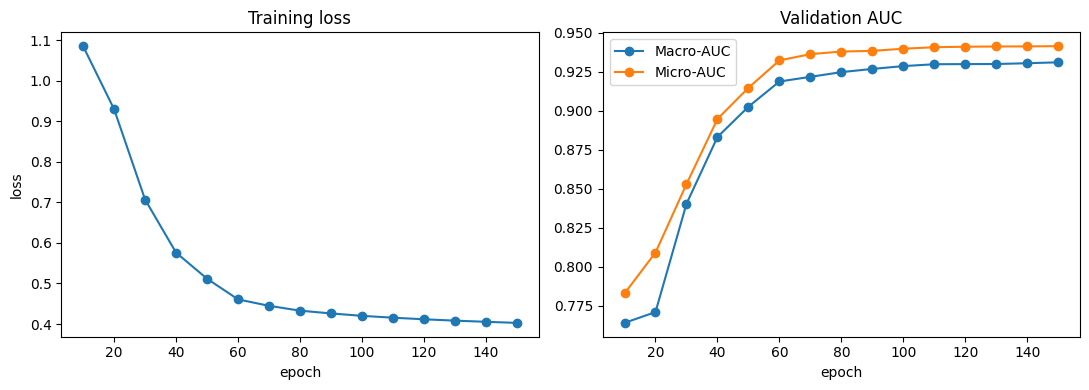

In [16]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history["epoch"], history["loss"], marker='o')
axes[0].set_title("Training loss"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss")

axes[1].plot(history["epoch"], history["val_macro_auc"], marker='o', label="Macro-AUC")
axes[1].plot(history["epoch"], history["val_micro_auc"], marker='o', label="Micro-AUC")
axes[1].set_title("Validation AUC"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout(); plt.show()


In [17]:
from sklearn.metrics import roc_auc_score
import pandas as pd

per_class_auc = {}
for i, cname in enumerate(class_names):
    yt = Y_run[test_mask_run][:, i]
    if len(np.unique(yt)) > 1:
        per_class_auc[cname] = roc_auc_score(yt, probs[test_mask_run][:, i])
    else:
        per_class_auc[cname] = float('nan')

pd.Series(per_class_auc, name="Test AUC").sort_values(ascending=False).to_frame()


,Test AUC
NORM,0.939233
MI,0.938023
STTC,0.911580
CD,0.910845
HYP,0.895551


In [18]:
import json

torch.save(model.state_dict(), '/kaggle/working/corgcn_ptbxl.pt')
with open('/kaggle/working/results.json', 'w') as f:
    json.dump({
        "config": {
            "label_level": LABEL_LEVEL, "feature_type": FEATURE_TYPE,
            "knn_k": KNN_K, "top_lambda": TOP_LAMBDA, "d": D,
            "n_layers": N_LAYERS, "n_subsample": N_SUBSAMPLE, "epochs": EPOCHS,
        },
        "class_names": class_names,
        "test_results": test_res,
        "per_class_auc": per_class_auc,
    }, f, indent=2)

print("Saved corgcn_ptbxl.pt and results.json to /kaggle/working")


Saved corgcn_ptbxl.pt and results.json to /kaggle/working
